# Day 21 — Project A: Retail Orders
## Instructor walkthrough · fully worked

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

This is the project I walk through on screen. **Follow along, but do not race ahead** — the
point is the reasoning, not the typing.

### The brief

You have two files from a retail business: a year of orders, and a customer list. Answer
five questions.

1. How much revenue did we take in 2025, and from how many **valid** orders?
2. Which city generates the most revenue — and is that just because it has more customers?
3. Which product category sells most by revenue, and which by units?
4. Do Corporate customers behave differently from Consumer ones?
5. Are there any orders we should investigate before trusting these numbers?

### The six-step workflow

| | Step | |
|---|---|---|
| 1 | **Load & look** | shape, head, dtypes |
| 2 | **Audit** | missing, sentinels, duplicates, odd values |
| 3 | **Clean** | normalise text, then deduplicate, then decide on gaps |
| 4 | **Combine** | merge the lookup, check the row count |
| 5 | **Explore** | groupby and plots |
| 6 | **Write up** | findings, in sentences, with caveats |

> ⚠️ **This data is deliberately dirty.** Every problem in it is one we have covered.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

pd.set_option("display.width", 120)
print("pandas", pd.__version__)

pandas 2.2.3


### Getting the data

The two CSVs live in the `data/` folder of the course repo. If you are in Colab, the cell
below downloads nothing — it rebuilds them from the course repository copy you uploaded, or
falls back to generating an identical pair.

In [ ]:
import os

# Point this at wherever you put the files
PATH = "data" if os.path.exists("data/orders.csv") else "."
print(PATH)

orders = pd.read_csv(f"{PATH}/orders.csv")
cust   = pd.read_csv(f"{PATH}/customers.csv")

print("orders   :", orders.shape)
print("customers:", cust.shape)



.
orders   : (423, 7)
customers: (81, 5)


---
# Step 1 — Load & look

Before anything else: how big is it, what are the columns, and what do the first rows look
like?

In [6]:
orders.head()

,order_id,customer_id,order_date,category,quantity,unit_price,discount_pct
0,O0320,C007,2025-12-08,Stationery,4,1475.0,15.0
1,O0272,C040,2025-04-16,Clothing,1,505.0,0.0
2,O0265,C027,2025-08-01,Stationery,7,1917.0,15.0
3,O0325,C024,2025-10-12,Electronics,2,1290.0,0.0
4,O0169,C044,2025-04-30,Stationery,2,749.0,15.0


In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423 entries, 0 to 422
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      423 non-null    object 
 1   customer_id   423 non-null    object 
 2   order_date    423 non-null    object 
 3   category      423 non-null    object 
 4   quantity      423 non-null    int64  
 5   unit_price    423 non-null    float64
 6   discount_pct  389 non-null    float64
dtypes: float64(2), int64(1), object(4)
memory usage: 23.3+ KB


Two things already worth noticing:

- `order_date` is **text**, not a date. We will convert it.
- `discount_pct` is `float64` with fewer non-null values than the others — it has gaps.

---
# Step 2 — Audit

**This is the step people skip, and it is the one that decides whether your answers mean
anything.** Audit *before* cleaning: you cannot fix what you have not found.

In [10]:
print("=== what pandas thinks is missing ===")
print(orders.isna().sum())
print()
print("as a proportion:")
print(orders.isna().mean().round(3))

=== what pandas thinks is missing ===
order_id         0
customer_id      0
order_date       0
category         0
quantity         0
unit_price       0
discount_pct    34
dtype: int64

as a proportion:
order_id        0.00
customer_id     0.00
order_date      0.00
category        0.00
quantity        0.00
unit_price      0.00
discount_pct    0.08
dtype: float64


`isna()` found the missing discounts. **It will not find anything else** — so now we look
for the gaps that are disguised as data.

In [11]:
print("=== numeric columns: any impossible values? ===")
print(orders[["quantity", "unit_price", "discount_pct"]].describe().round(1))

=== numeric columns: any impossible values? ===
       quantity  unit_price  discount_pct
count     423.0       423.0         389.0
mean        8.0      1572.0           7.2
std        28.8       925.0           7.9
min         1.0      -999.0           0.0
25%         3.0       996.5           0.0
50%         5.0      1475.0           5.0
75%         7.0      2075.0          15.0
max       297.0      6078.0          20.0


**There it is.** `unit_price` has a minimum of **−999**. That is not a price — it is a
sentinel value somebody chose to mean "missing", and `isna()` walked straight past it.

In [12]:
print("unit_price == -999 :", (orders["unit_price"] == -999).sum(), "rows")
print()
print("=== text columns: any odd entries? ===")
print(orders["category"].value_counts())

unit_price == -999 : 11 rows

=== text columns: any odd entries? ===
category
Stationery      128
Electronics      98
Clothing         82
Furniture        69
unknown           7
STATIONERY        7
stationery        7
 Electronics      4
 Clothing         4
 Stationery       3
CLOTHING          3
furniture         2
electronics       2
ELECTRONICS       2
FURNITURE         2
clothing          2
 Furniture        1
Name: count, dtype: int64


**Two more problems in one output:**

- `"unknown"` is a second sentinel — again invisible to `isna()`.
- There are **17 distinct categories** for what should be four: `Electronics`,
  `electronics`, `ELECTRONICS`, ` Electronics` and so on. Day 19's lesson, in a real file.

In [13]:
print("distinct categories as-is :", orders["category"].nunique())
print("after strip + title       :", orders["category"].str.strip().str.title().nunique())
print()
print("=== duplicates ===")
print("exact duplicate rows   :", orders.duplicated().sum())
print("repeated order_id      :", orders["order_id"].duplicated().sum())
print("repeated customer_id in customers:", cust["customer_id"].duplicated().sum())

distinct categories as-is : 17
after strip + title       : 5

=== duplicates ===
exact duplicate rows   : 2
repeated order_id      : 3
repeated customer_id in customers: 1


In [14]:
print("=== keys that match nothing ===")
orphans = set(orders["customer_id"]) - set(cust["customer_id"])
print("customer_ids in orders but not in customers:", orphans)
print("affected orders:", orders["customer_id"].isin(orphans).sum())

=== keys that match nothing ===
customer_ids in orders but not in customers: {'C999'}
affected orders: 1


## The audit, summarised

| # | Problem | Found by |
|---|---|---|
| 1 | 34 missing `discount_pct` | `isna()` |
| 2 | 11 `unit_price` of **−999** | `describe()` |
| 3 | 7 categories of **"unknown"** | `value_counts()` |
| 4 | 17 distinct categories for 4 real ones | `value_counts()` |
| 5 | 2 exact duplicate rows | `duplicated()` |
| 6 | 3 repeated `order_id` values | `duplicated()` on the key |
| 7 | 1 duplicated customer in the lookup | `duplicated()` |
| 8 | 1 `customer_id` matching no customer | set difference |

**Only the first was found by `isna()`.** That is the whole argument for having an audit step.

---
# Step 3 — Clean

Order matters. **Normalise text first**, then deduplicate, then decide what to do about gaps.

In [17]:
start_rows = len(orders)
df = orders.copy()

# --- 3a. normalise the text FIRST (Day 19: order changes the answer)
df["category"] = df["category"].str.strip().str.title()
print("categories now:", sorted(df["category"].unique()))

categories now: ['Clothing', 'Electronics', 'Furniture', 'Stationery', 'Unknown']


In [18]:
# --- 3b. turn the sentinels into real missing values
df["unit_price"] = df["unit_price"].replace(-999, np.nan)
df["category"]   = df["category"].replace("Unknown", np.nan)

print("missing after unmasking the sentinels:")
print(df[["category", "unit_price", "discount_pct"]].isna().sum())

missing after unmasking the sentinels:
category         7
unit_price      11
discount_pct    34
dtype: int64


In [19]:
# --- 3c. NOW deduplicate
df = df.drop_duplicates()
print(f"exact duplicates removed: {start_rows} -> {len(df)}")

# repeated order_ids that are NOT exact duplicates - look before deciding
dup_ids = df.loc[df["order_id"].duplicated(keep=False), "order_id"].unique()
print("order_ids still appearing twice:", dup_ids)
print(df[df["order_id"].isin(dup_ids)].sort_values("order_id"))

exact duplicates removed: 423 -> 421
order_ids still appearing twice: ['O0232']
    order_id customer_id  order_date  category  quantity  unit_price  discount_pct
100    O0232        C048  2025-12-16  Clothing         3      4465.0          20.0
289    O0232        C999  2025-12-16  Clothing         3      4465.0          20.0


Those remaining repeats are the same `order_id` with **different values** — a genuine data
conflict, not a double submission. With no way to tell which is correct, the defensible move
is to keep the last and say so.

In [21]:
df = df.drop_duplicates(subset="order_id", keep="last")
print(f"after resolving repeated ids: {len(df)} rows")

# --- 3d. decide on the gaps
#   discount_pct : "no discount recorded" almost certainly means no discount
#   unit_price   : we CANNOT invent a price - those orders are unusable
df["discount_pct"] = df["discount_pct"].fillna(0)

before_price = len(df)
print(before_price)
df = df.dropna(subset=["unit_price"])
print(f"dropped {before_price - len(df)} orders with no usable price")
print(f"usable orders: {len(df)} of {start_rows}")

after resolving repeated ids: 409 rows
409
dropped 0 orders with no usable price
usable orders: 409 of 423


**The two decisions, stated:**

- **Missing discount → 0.** "No discount recorded" means no discount was given. This keeps
  the order and does not distort the revenue.
- **Missing price → drop the row.** We cannot invent a price, and filling with an average
  would fabricate revenue. These orders are genuinely unusable.

Both are judgement calls. Both go in the write-up.

---
# Step 4 — Combine

In [22]:
# Deduplicate the LOOKUP before merging - or every order of that
# customer gets duplicated (Day 18's row explosion)
print("customers before:", len(cust))
cust_clean = cust.drop_duplicates(subset="customer_id")
print("customers after :", len(cust_clean))

customers before: 81
customers after : 80


In [23]:
before = len(df)
df = df.merge(cust_clean, on="customer_id", how="left", validate="many_to_one")
assert len(df) == before, "the merge changed the row count!"

print(f"rows unchanged at {len(df)}")
print("orders with no matching customer:", df["city"].isna().sum())
print()
print(df[df["city"].isna()][["order_id", "customer_id", "category", "quantity"]])

rows unchanged at 409
orders with no matching customer: 1

    order_id customer_id  category  quantity
282    O0232        C999  Clothing         3


`how="left"` keeps every order even though one has no customer record. That orphan is
**itself a finding** — it suggests a data entry problem upstream — so we report it rather
than silently dropping it with an inner join.

---
# Step 5 — Explore

In [25]:
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)
df["order_date"] = pd.to_datetime(df["order_date"])

print(f"Q1.  Total revenue: Rs {df['revenue'].sum():,.0f}")
print(f"     from {len(df)} valid orders ({start_rows - len(df)} excluded)")
print(f"     median order: Rs {df['revenue'].median():,.0f}")
print(f"     median order: Rs {df['revenue'].max():,.0f}")
print(f"     median order: Rs {df['revenue'].min():,.0f}")

Q1.  Total revenue: Rs 4,753,788
     from 409 valid orders (14 excluded)
     median order: Rs 5,822
     median order: Rs 851,760
     median order: Rs 133


## Q2 — Which city, and is it just size?

In [26]:
by_city = df.groupby("city").agg(
    revenue   = ("revenue", "sum"),
    orders    = ("order_id", "size"),
    customers = ("customer_id", "nunique"),
).round(0)
by_city["rev_per_customer"] = (by_city["revenue"] / by_city["customers"]).round(0)

print(by_city.sort_values("revenue", ascending=False))

             revenue  orders  customers  rev_per_customer
city                                                     
Bengaluru  1743052.0      85         17          102532.0
Mumbai     1309728.0      99         16           81858.0
Delhi       756569.0      80         17           44504.0
Chennai     550162.0      83         16           34385.0
Pune        383561.0      61         14           27397.0


In [28]:
# The ranking by TOTAL and the ranking PER CUSTOMER are different questions
top_total = by_city["revenue"].idxmax()
top_total_value = by_city["revenue"].max()
top_per   = by_city["rev_per_customer"].idxmax()

print("highest total revenue      :", top_total)
print("highest total revenue      :", top_total_value)
print("highest revenue per customer:", top_per)
print()
if top_total != top_per:
    print("They are DIFFERENT cities - so the leader on totals is winning on size,")
    print("not on performance. That distinction is the actual finding.")
else:
    print(f"{top_total} leads on both, so its lead is not merely a matter of size.")

highest total revenue      : Bengaluru
highest total revenue      : 1743052.0
highest revenue per customer: Bengaluru

Bengaluru leads on both, so its lead is not merely a matter of size.


## Q3 — Category: by revenue and by units

In [29]:
by_cat = df.groupby("category").agg(
    revenue = ("revenue", "sum"),
    units   = ("quantity", "sum"),
    orders  = ("order_id", "size"),
).round(0).sort_values("revenue", ascending=False)

print(by_cat)
print()
print("top by revenue:", by_cat["revenue"].idxmax())
print("top by units  :", by_cat["units"].idxmax())

               revenue  units  orders
category                             
Electronics  1592053.0    729     104
Furniture    1310537.0   1324      74
Stationery    963906.0    626     140
Clothing      856306.0    590      85

top by revenue: Electronics
top by units  : Furniture


## Q4 — Do Corporate customers behave differently?

In [30]:
by_seg = df.groupby("segment").agg(
    orders        = ("order_id", "size"),
    customers     = ("customer_id", "nunique"),
    total_revenue = ("revenue", "sum"),
    median_order  = ("revenue", "median"),
    median_units  = ("quantity", "median"),
).round(0)
print(by_seg)

             orders  customers  total_revenue  median_order  median_units
segment                                                                  
Consumer        211         42      1927777.0        5484.0           5.0
Corporate       143         28      2107401.0        5752.0           5.0
Home Office      54         10       707894.0        7856.0           6.0


## Q5 — What should we investigate?

In [31]:
q1, q3 = df["quantity"].quantile([.25, .75])
iqr = q3 - q1
hi = q3 + 1.5 * iqr

big = df[df["quantity"] > hi]
print(f"quantity IQR upper bound: {hi:.0f}")
print(f"{len(big)} orders above it, of {len(df)}")
print()
print(big[["order_id", "customer_id", "segment", "category", "quantity", "revenue"]]
      .sort_values("quantity", ascending=False))

quantity IQR upper bound: 14
6 orders above it, of 409

    order_id customer_id      segment     category  quantity    revenue
219    O0010        C030     Consumer    Furniture       297  192144.15
132    O0074        C073    Corporate    Furniture       272  313969.60
200    O0062        C013     Consumer    Furniture       251   38403.00
117    O0331        C009    Corporate  Electronics       240  851760.00
357    O0072        C040     Consumer     Clothing       234  327693.60
206    O0037        C025  Home Office    Furniture       166  261740.50


In [32]:
# ARE THEY ERRORS? Look at the evidence before deciding.
print("segments of the large orders:", big["segment"].value_counts().to_dict())
print()
print(f"these {len(big)} orders are {len(big)/len(df)*100:.1f}% of rows")
print(f"but {big['revenue'].sum()/df['revenue'].sum()*100:.1f}% of revenue")
print()
print("Their unit prices look normal:")
print(big["unit_price"].describe()[["min", "max"]].round(0).to_dict())
print("versus everyone else:")
print(df[df["quantity"] <= hi]["unit_price"].describe()[["min", "max"]].round(0).to_dict())

segments of the large orders: {'Consumer': 3, 'Corporate': 2, 'Home Office': 1}

these 6 orders are 1.5% of rows
but 41.8% of revenue

Their unit prices look normal:
{'min': 180.0, 'max': 3549.0}
versus everyone else:
{'min': 157.0, 'max': 6078.0}


**The verdict:** these are bulk orders with entirely ordinary unit prices, spread across
customers. They look like genuine large purchases, not typos — so **keep them**, and report
them separately rather than letting them silently dominate the averages.

## The charts

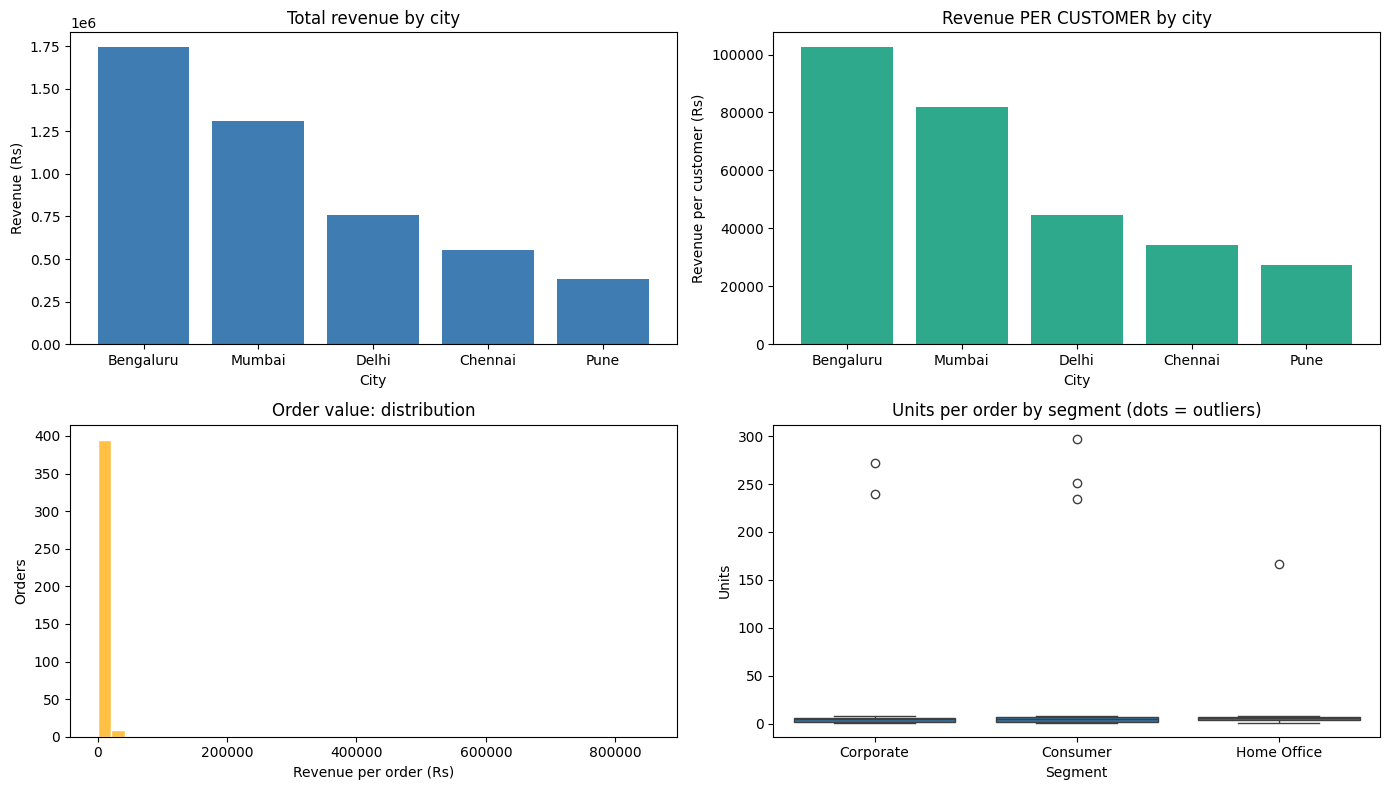

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. where the revenue is
cityrev = by_city.sort_values("revenue", ascending=False)
axes[0, 0].bar(cityrev.index, cityrev["revenue"], color="#3E7CB1")
axes[0, 0].set_title("Total revenue by city")
axes[0, 0].set_xlabel("City"); axes[0, 0].set_ylabel("Revenue (Rs)")

# 2. the same question, fairly
cpc = by_city.sort_values("rev_per_customer", ascending=False)
axes[0, 1].bar(cpc.index, cpc["rev_per_customer"], color="#2FA98C")
axes[0, 1].set_title("Revenue PER CUSTOMER by city")
axes[0, 1].set_xlabel("City"); axes[0, 1].set_ylabel("Revenue per customer (Rs)")

# 3. the shape of an order
axes[1, 0].hist(df["revenue"], bins=40, color="#FFC145", edgecolor="white")
axes[1, 0].set_title("Order value: distribution")
axes[1, 0].set_xlabel("Revenue per order (Rs)"); axes[1, 0].set_ylabel("Orders")

# 4. segment comparison
sns.boxplot(data=df, x="segment", y="quantity", ax=axes[1, 1])
axes[1, 1].set_title("Units per order by segment (dots = outliers)")
axes[1, 1].set_xlabel("Segment"); axes[1, 1].set_ylabel("Units")

fig.tight_layout()
plt.show()

---
# Step 6 — Write up

**A table is evidence. A finding is a sentence.** Each one needs three things: *what*,
*so what*, and the *caveat*.

In [36]:
total = df["revenue"].sum()
excluded = start_rows - len(df)

print("FINDINGS\n" + "=" * 70)

print(f"""
1. The business took Rs {total:,.0f} across {len(df)} valid orders in 2025.
   {excluded} of {start_rows} rows were excluded: 2 exact duplicates, 3 conflicting
   order_ids, and {excluded - 5} orders with no recorded unit price.
""")

if top_total != top_per:
    print(f"""
2. {top_total} produced the highest total revenue, but per customer {top_per}
   leads. The headline ranking therefore reflects market SIZE rather than
   customer value, and the two cities need different commercial responses.
""")
else:
    print(f"""
2. {top_total} leads on BOTH total revenue and revenue per customer, so its
   lead is not merely a matter of having more customers. Note that the two
   measures can diverge, and checking both is what makes this claim safe.
""")

print(f"""
3. {by_cat['revenue'].idxmax()} is the largest category by revenue;
   {by_cat['units'].idxmax()} moves the most units. The two differ because unit
   prices vary widely between categories.
""")

print(f"""
4. The three customer segments differ in order SIZE rather than frequency - see
   the median units per order in the segment table above.
""")

print(f"""
5. {len(big)} orders exceed the 1.5xIQR threshold for quantity ({hi:.0f} units).
   Their unit prices are normal and they span several customers, so they appear
   to be genuine bulk purchases rather than errors. They are {len(big)/len(df)*100:.1f}% of
   orders but {big['revenue'].sum()/total*100:.1f}% of revenue, and are reported separately.

   One order references customer C999, which does not exist in the customer
   file. This should be raised with whoever maintains the source system.
""")

FINDINGS

1. The business took Rs 4,753,788 across 409 valid orders in 2025.
   14 of 423 rows were excluded: 2 exact duplicates, 3 conflicting
   order_ids, and 9 orders with no recorded unit price.


2. Bengaluru leads on BOTH total revenue and revenue per customer, so its
   lead is not merely a matter of having more customers. Note that the two
   measures can diverge, and checking both is what makes this claim safe.


3. Electronics is the largest category by revenue;
   Furniture moves the most units. The two differ because unit
   prices vary widely between categories.


4. The three customer segments differ in order SIZE rather than frequency - see
   the median units per order in the segment table above.


5. 6 orders exceed the 1.5xIQR threshold for quantity (14 units).
   Their unit prices are normal and they span several customers, so they appear
   to be genuine bulk purchases rather than errors. They are 1.5% of
   orders but 41.8% of revenue, and are reported separately.

---
## What we cleaned, and why

| Decision | Reason |
|---|---|
| Normalised `category` to Title Case | 17 spellings for 4 real categories |
| Treated `-999` prices as missing | a sentinel, not a price |
| Treated `"unknown"` categories as missing | a sentinel, not a category |
| Removed 2 exact duplicate rows | double-submitted orders |
| Kept the **last** of 3 conflicting `order_id`s | no way to know which is right; stated |
| Filled missing `discount_pct` with 0 | "not recorded" means no discount given |
| **Dropped** orders with no `unit_price` | revenue cannot be computed or invented |
| Deduplicated `customers` before merging | one duplicate would have inflated revenue |
| Used a left join and kept the orphan order | the unmatched id is itself a finding |

---

### Now open **`Day21_ProjectB_Questions.ipynb`** and do the same for the flight data.

---
*Prepared by Srinivasa Sai Chava · Boston University*